# Tau Bar Plot

This notebook reads the summary CSV files for the different split selections and builds a grouped bar plot with stderr whiskers.

Customize the input folder, the plotted value column, and the output path in the code cell below.

This file contains code written by AI.

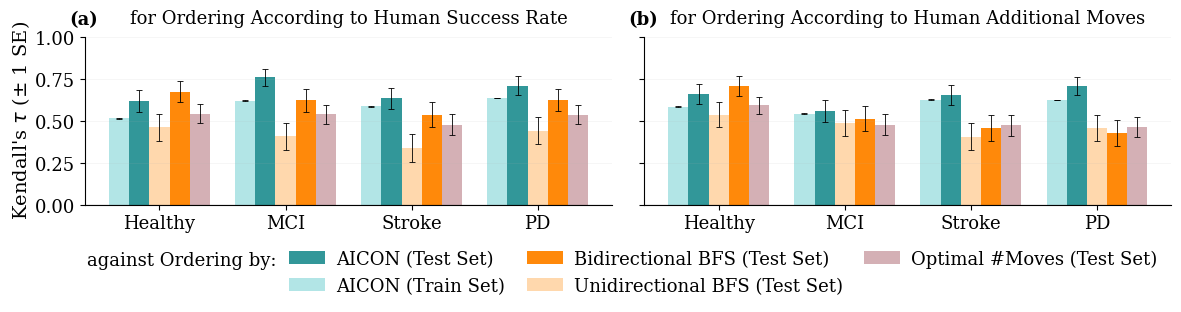

Saved plot to: c:\Users\Michael Migacev\Desktop\UNI\Wirklich_UNI\AICON\master-thesis-tol\master-thesis-tol\tower_of_london_plots\tables\boxed_totals_1x2_5bars_despined.pdf


In [ ]:
# New variant (keeps previous cells unchanged)
from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

CSV_FOLDER_LOCAL = Path(r"c:\Users\Michael Migacev\Desktop\UNI\Wirklich_UNI\AICON\master-thesis-tol\master-thesis-tol\tower_of_london_plots\tables")
SELECTION_SUFFIXES_LOCAL = ["all", "easy_v_easy", "easy_v_hard", "hard_v_hard"]
SELECTION_PATTERN_LOCAL = re.compile(r"_sim_.*_(all|easy_v_easy|easy_v_hard|hard_v_hard)\.csv$")
SELECTION_SPLIT_SIZES_LOCAL = {"all": 120, "easy_v_easy": 30, "easy_v_hard": 60, "hard_v_hard": 30}
PATIENT_ORDER_LOCAL = ["Healthy", "MCI", "Stroke","PD"]
SERIES_INFO_LOCAL = [
    ("avg_train_mean", "avg_train_std", "AICON (Train Set)", "#B2E5E6"),
    ("avg_test_mean", "avg_test_std", "AICON (Test Set)", "#329799"),
    ("avg_bfs_simple_mean", "avg_bfs_simple_std", "Unidirectional BFS (Test Set)", "#FFD8AD"),
    ("avg_bfs_mean", "avg_bfs_std", "Bidirectional BFS (Test Set)", "#FF890A"),
    ("avg_opt_mov_mean", "avg_opt_mov_std", "Optimal #Moves (Test Set)", "#D4B0B5"),
]

def _configure_style() -> None:
    plt.rcParams.update({
        "font.family": "serif",
        "font.serif": ["Computer Modern Roman", "DejaVu Serif"],
        "axes.titlesize": 13,
        "axes.labelsize": 13,
        "font.size": 13,
        "xtick.labelsize": 13,
        "ytick.labelsize": 13,
        "figure.facecolor": "white",
        "axes.facecolor": "white",
    })


def _find_selection_csv(folder: Path, selection: str) -> Path:
    matches = sorted(folder.glob(f"*_sim_*_{selection}.csv"))
    if not matches:
        raise FileNotFoundError(f"No CSV found for selection {selection!r} in {folder}")
    return matches[0]


def _load_summary_table(csv_path: Path) -> pd.DataFrame:
    frame = pd.read_csv(csv_path)
    required_columns = {"comparison_metric","patient_group","avg_train_mean","avg_train_std","avg_test_mean","avg_test_std","avg_bfs_mean","avg_bfs_std","avg_bfs_simple_mean","avg_bfs_simple_std","avg_opt_mov_mean","avg_opt_mov_std"}
    missing_columns = required_columns - set(frame.columns)
    if missing_columns:
        raise ValueError(f"{csv_path} is missing columns: {sorted(missing_columns)}")
    selection_match = SELECTION_PATTERN_LOCAL.search(csv_path.name)
    if not selection_match:
        raise ValueError(f"Could not infer split selection from file name: {csv_path.name}")
    frame = frame.copy(); frame["selection"] = selection_match.group(1)
    return frame


def _load_all_tables(folder: Path, suffixes: list[str]) -> pd.DataFrame:
    frames = []
    for selection in suffixes:
        frames.append(_load_summary_table(_find_selection_csv(folder, selection)))
    return pd.concat(frames, ignore_index=True)


def _get_row(data_frame: pd.DataFrame, selection: str, metric: str, patient_group: str) -> pd.Series:
    row = data_frame[(data_frame["selection"] == selection)&(data_frame["comparison_metric"] == metric)&(data_frame["patient_group"] == patient_group)]
    if row.empty:
        raise ValueError(f"Missing row for {selection} / {metric} / {patient_group}")
    return row.iloc[0]


def _get_stderr(std_value: float, selection: str) -> float:
    return std_value / np.sqrt(SELECTION_SPLIT_SIZES_LOCAL[selection])


def _style_box_axes(ax: plt.Axes) -> None:
    for spine in ax.spines.values():
        spine.set_visible(False)
        spine.set_linewidth(0.8)
    ax.spines['left'].set_visible(True)
    ax.spines['bottom'].set_visible(True) 
    ax.grid(axis="y", alpha=0.15, linewidth=0.5); ax.axhline(0, color="black", linewidth=0.8, alpha=0.8)


def _draw_panel(
    ax: plt.Axes,
    df: pd.DataFrame,
    selection: str,
    metric: str,
    title: str,
    panel_letter: str | None = None,
    top_row: bool = False,
    y_limits: tuple[float, float] = (0.0, 1.0),
) -> None:
    x = np.arange(len(PATIENT_ORDER_LOCAL))
    n_series = len(SERIES_INFO_LOCAL)
    bar_width = (1.0 / n_series) * 0.8
    offsets = (np.arange(n_series) - (n_series - 1) / 2) * bar_width
    for offset, (mean_col, std_col, label, color) in zip(offsets, SERIES_INFO_LOCAL):
        means = []; errors = []
        for patient_group in PATIENT_ORDER_LOCAL:
            row = _get_row(df, selection, metric, patient_group)
            means.append(float(row[mean_col])); errors.append(_get_stderr(float(row[std_col]), selection))
        ax.bar(
            x + offset,
            means,
            width=bar_width,
            yerr=errors,
            capsize=2,
            color=color,
            edgecolor="none",
            linewidth=0,
            label=label,
            error_kw={"elinewidth": 0.6, "capthick": 0.6},
        )
    ax.set_title(title, loc="center", pad=10, fontfamily="serif")
    if panel_letter is not None:
        ax.text(
            -0.03,
            1.05,
            f"({panel_letter})",
            transform=ax.transAxes,
            ha="left",
            va="bottom",
            fontfamily="serif",
            fontweight="bold",
        )
    ax.set_xticks(x); ax.set_xticklabels(PATIENT_ORDER_LOCAL)
    if top_row:
        ax.tick_params(labelbottom=False, bottom=False)
        ax.spines['bottom'].set_visible(False)
    ax.set_ylim(*y_limits); _style_box_axes(ax)


_configure_style()
summary_frame_local = _load_all_tables(CSV_FOLDER_LOCAL, SELECTION_SUFFIXES_LOCAL)

fig_a, axes_a = plt.subplots(1, 2, figsize=(12, 3), sharex=True, sharey=True)
_draw_panel(
    axes_a[0],
    summary_frame_local,
    "all",
    "success_rate_rev",
    "for Ordering According to Human Success Rate",
    panel_letter="a",
    y_limits=(0.0, 1.0),
)
_draw_panel(
    axes_a[1],
    summary_frame_local,
    "all",
    "mean_extra_moves_on_success",
    "for Ordering According to Human Additional Moves",
    panel_letter="b",
    y_limits=(0.0, 1.0),
)
handles_a, labels_a = axes_a[0].get_legend_handles_labels()
legend_order = [
    "AICON (Test Set)",
    "AICON (Train Set)",
    "Bidirectional BFS (Test Set)",
    "Unidirectional BFS (Test Set)",
    "Optimal #Moves (Test Set)",
]
ordered_handles = [handles_a[labels_a.index(label)] for label in legend_order]
#fig_a.supylabel(r"Kendall's $\tau$ ($\pm$ 1 SE)")
fig_a.text(
    0.025,
    0.44,
    "Kendall's $\\tau$ ($\\pm$ 1 SE)",
    rotation=90,
    ha="center",
    va="center",
    fontfamily="serif",
    fontsize=14,
)
fig_a.text(0.08, 0.004, "against Ordering by:", ha="left", va="top", fontfamily="serif")
fig_a.legend(
    ordered_handles,
    legend_order,
    frameon=False,
    ncols=3,
    loc="upper left",
    bbox_to_anchor=(0.25, 0.002),
    columnspacing=1.2,
    handletextpad=0.6,
    borderaxespad=-0.5,
)
fig_a.tight_layout(rect=(0.03, 0, 1, 0.88))
out_a = CSV_FOLDER_LOCAL / "boxed_totals_1x2_5bars_despined.pdf"
fig_a.savefig(out_a, dpi=300, bbox_inches="tight")
plt.show(); plt.close(fig_a)


print(f"Saved plot to: {out_a}")

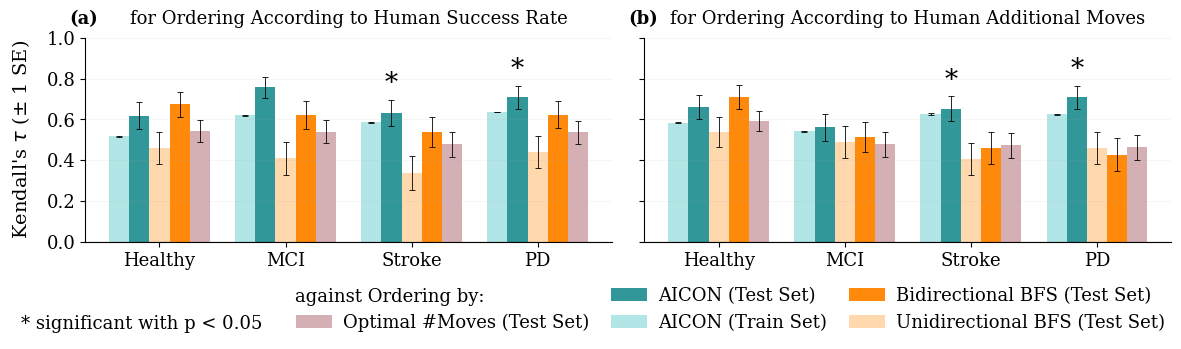

Saved plot to: c:\Users\Michael Migacev\Desktop\UNI\Wirklich_UNI\AICON\master-thesis-tol\master-thesis-tol\tower_of_london_plots\tables\boxed_totals_1x2_5bars_despined_asterisk_long.pdf


In [ ]:
# New variant (keeps previous cells unchanged)
from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

CSV_FOLDER_LOCAL = Path(r"c:\Users\Michael Migacev\Desktop\UNI\Wirklich_UNI\AICON\master-thesis-tol\master-thesis-tol\tower_of_london_plots\tables")
SELECTION_SUFFIXES_LOCAL = ["all", "easy_v_easy", "easy_v_hard", "hard_v_hard"]
SELECTION_PATTERN_LOCAL = re.compile(r"_sim_.*_(all|easy_v_easy|easy_v_hard|hard_v_hard)\.csv$")
SELECTION_SPLIT_SIZES_LOCAL = {"all": 120, "easy_v_easy": 30, "easy_v_hard": 60, "hard_v_hard": 30}
PATIENT_ORDER_LOCAL = ["Healthy", "MCI", "Stroke","PD"]
SERIES_INFO_LOCAL = [
    ("avg_train_mean", "avg_train_std", "AICON (Train Set)", "#B2E5E6"),
    ("avg_test_mean", "avg_test_std", "AICON (Test Set)", "#329799"),
    ("avg_bfs_simple_mean", "avg_bfs_simple_std", "Unidirectional BFS (Test Set)", "#FFD8AD"),
    ("avg_bfs_mean", "avg_bfs_std", "Bidirectional BFS (Test Set)", "#FF890A"),
    ("avg_opt_mov_mean", "avg_opt_mov_std", "Optimal #Moves (Test Set)", "#D4B0B5"),
]

def _configure_style() -> None:
    plt.rcParams.update({
        "font.family": "serif",
        "font.serif": ["Computer Modern Roman", "DejaVu Serif"],
        "axes.titlesize": 13,
        "axes.labelsize": 13,
        "font.size": 13,
        "xtick.labelsize": 13,
        "ytick.labelsize": 13,
        "figure.facecolor": "white",
        "axes.facecolor": "white",
    })

def add_asterisk(
    ax: plt.Axes,
    df: pd.DataFrame,
    selection: str,
    metric: str,
    patient_groups: list[str],
    series_index: int = 1,          # default: AICON (Test Set)
    y_offset: float = 0.02,         # extra space above error bar (in data coords)
    symbol: str = "*",
    fontsize: int = 30,
    color: str = "black",
) -> None:
    """
    Annotate bars with an asterisk (or any symbol) above the error bar.

    Parameters
    ----------
    ax : matplotlib Axes
    df : DataFrame with summary data
    selection : str, e.g. "all"
    metric : str, e.g. "success_rate_rev"
    patient_groups : list of group names to annotate, e.g. ["PD", "Stroke"]
    series_index : int, index in SERIES_INFO_LOCAL (0-based)
    y_offset : float, additional vertical offset from the top of the error bar
    symbol : str, the annotation text
    fontsize : int
    color : str
    """
    # retrieve offsets (same calculation as in _draw_panel)
    n_series = len(SERIES_INFO_LOCAL)
    bar_width = (1.0 / n_series) * 0.8
    offsets = (np.arange(n_series) - (n_series - 1) / 2) * bar_width
    x_offset = offsets[series_index]

    # get the relevant columns for this series
    mean_col, std_col, _, _ = SERIES_INFO_LOCAL[series_index]

    # patient index mapping
    patient_to_idx = {name: i for i, name in enumerate(PATIENT_ORDER_LOCAL)}

    for group in patient_groups:
        if group not in patient_to_idx:
            raise ValueError(f"Unknown patient group: {group}")
        idx = patient_to_idx[group]

        row = _get_row(df, selection, metric, group)
        mean = float(row[mean_col])
        std = float(row[std_col])
        stderr = std / np.sqrt(SELECTION_SPLIT_SIZES_LOCAL[selection])

        x = idx + x_offset
        y = mean + stderr + y_offset

        ax.text(
            x, y, symbol,
            ha="center",
            va="bottom",
            fontsize=fontsize,
            color=color,
            fontfamily="serif",
        )

def _find_selection_csv(folder: Path, selection: str) -> Path:
    matches = sorted(folder.glob(f"*_sim_*_{selection}.csv"))
    if not matches:
        raise FileNotFoundError(f"No CSV found for selection {selection!r} in {folder}")
    return matches[0]


def _load_summary_table(csv_path: Path) -> pd.DataFrame:
    frame = pd.read_csv(csv_path)
    required_columns = {"comparison_metric","patient_group","avg_train_mean","avg_train_std","avg_test_mean","avg_test_std","avg_bfs_mean","avg_bfs_std","avg_bfs_simple_mean","avg_bfs_simple_std","avg_opt_mov_mean","avg_opt_mov_std"}
    missing_columns = required_columns - set(frame.columns)
    if missing_columns:
        raise ValueError(f"{csv_path} is missing columns: {sorted(missing_columns)}")
    selection_match = SELECTION_PATTERN_LOCAL.search(csv_path.name)
    if not selection_match:
        raise ValueError(f"Could not infer split selection from file name: {csv_path.name}")
    frame = frame.copy(); frame["selection"] = selection_match.group(1)
    return frame


def _load_all_tables(folder: Path, suffixes: list[str]) -> pd.DataFrame:
    frames = []
    for selection in suffixes:
        frames.append(_load_summary_table(_find_selection_csv(folder, selection)))
    return pd.concat(frames, ignore_index=True)


def _get_row(data_frame: pd.DataFrame, selection: str, metric: str, patient_group: str) -> pd.Series:
    row = data_frame[(data_frame["selection"] == selection)&(data_frame["comparison_metric"] == metric)&(data_frame["patient_group"] == patient_group)]
    if row.empty:
        raise ValueError(f"Missing row for {selection} / {metric} / {patient_group}")
    return row.iloc[0]


def _get_stderr(std_value: float, selection: str) -> float:
    return std_value / np.sqrt(SELECTION_SPLIT_SIZES_LOCAL[selection])


def _style_box_axes(ax: plt.Axes) -> None:
    for spine in ax.spines.values():
        spine.set_visible(False)
        spine.set_linewidth(0.8)
    ax.spines['left'].set_visible(True)
    ax.spines['bottom'].set_visible(True) 
    ax.grid(axis="y", alpha=0.15, linewidth=0.5); ax.axhline(0, color="black", linewidth=0.8, alpha=0.8)


def _draw_panel(
    ax: plt.Axes,
    df: pd.DataFrame,
    selection: str,
    metric: str,
    title: str,
    panel_letter: str | None = None,
    top_row: bool = False,
    y_limits: tuple[float, float] = (0.0, 1.0),
) -> None:
    x = np.arange(len(PATIENT_ORDER_LOCAL))
    n_series = len(SERIES_INFO_LOCAL)
    bar_width = (1.0 / n_series) * 0.8
    offsets = (np.arange(n_series) - (n_series - 1) / 2) * bar_width
    for offset, (mean_col, std_col, label, color) in zip(offsets, SERIES_INFO_LOCAL):
        means = []; errors = []
        for patient_group in PATIENT_ORDER_LOCAL:
            row = _get_row(df, selection, metric, patient_group)
            means.append(float(row[mean_col])); errors.append(_get_stderr(float(row[std_col]), selection))
        ax.bar(
            x + offset,
            means,
            width=bar_width,
            yerr=errors,
            capsize=2,
            color=color,
            edgecolor="none",
            linewidth=0,
            label=label,
            error_kw={"elinewidth": 0.6, "capthick": 0.6},
        )
    ax.set_title(title, loc="center", pad=10, fontfamily="serif")
    if panel_letter is not None:
        ax.text(
            -0.03,
            1.05,
            f"({panel_letter})",
            transform=ax.transAxes,
            ha="left",
            va="bottom",
            fontfamily="serif",
            fontweight="bold",
        )
    ax.set_xticks(x); ax.set_xticklabels(PATIENT_ORDER_LOCAL)
    if top_row:
        ax.tick_params(labelbottom=False, bottom=False)
        ax.spines['bottom'].set_visible(False)
    ax.set_ylim(*y_limits); _style_box_axes(ax)


_configure_style()
summary_frame_local = _load_all_tables(CSV_FOLDER_LOCAL, SELECTION_SUFFIXES_LOCAL)

fig_a, axes_a = plt.subplots(1, 2, figsize=(12, 3), sharex=True, sharey=True)
_draw_panel(
    axes_a[0],
    summary_frame_local,
    "all",
    "success_rate_rev",
    "for Ordering According to Human Success Rate",
    panel_letter="a",
    y_limits=(0.0, 1.0),
)
_draw_panel(
    axes_a[1],
    summary_frame_local,
    "all",
    "mean_extra_moves_on_success",
    "for Ordering According to Human Additional Moves",
    panel_letter="b",
    y_limits=(0.0, 1.0),
)
for ax, metric in zip(axes_a, ["success_rate_rev", "mean_extra_moves_on_success"]):
    add_asterisk(
        ax=ax,
        df=summary_frame_local,
        selection="all",
        metric=metric,
        patient_groups=["PD", "Stroke"],   # annotate both
        series_index=1,                    # AICON (Test Set)
        y_offset=0.02,                    # adjust this to move symbol up/down
        symbol="*",
        fontsize=19,
        color="black",
    )
from matplotlib.patches import Rectangle

handles_a, labels_a = axes_a[0].get_legend_handles_labels()
legend_order = [
    "Optimal #Moves (Test Set)",
    "AICON (Test Set)",
    "AICON (Train Set)",
    "Bidirectional BFS (Test Set)",
    "Unidirectional BFS (Test Set)",
]
ordered_handles = [handles_a[labels_a.index(label)] for label in legend_order]

dummy_handle = Rectangle(
    (0, 0), 0, 0, fill=False, linewidth=0, alpha=0, edgecolor="none"
)

# Prepend the dummy so the legend grid becomes 2 rows × 3 cols
all_handles = [dummy_handle] + ordered_handles
all_labels  = ["     "] + legend_order

#fig_a.supylabel(r"Kendall's $\tau$ ($\pm$ 1 SE)")
fig_a.text(
    0.025,
    0.5,
    "Kendall's $\\tau$ ($\\pm$ 1 SE)",
    rotation=90,
    ha="center",
    va="center",
    fontfamily="serif",
    fontsize=14,
)
fig_a.text(0.253, 0.004, "against Ordering by:", ha="left", va="top", fontfamily="serif")
fig_a.legend(
    all_handles,
    all_labels,
    frameon=False,
    ncols=3,
    loc="upper left",
    bbox_to_anchor=(0.256, 0.002),
    columnspacing=1.2,
    handletextpad=0.6,
    borderaxespad=-0.5,
)
fig_a.text(0.025, -0.085, "* significant with p < 0.05", ha="left", va="top", fontfamily="serif")
fig_a.tight_layout(rect=(0.03, 0, 1, 1))
out_a = CSV_FOLDER_LOCAL / "boxed_totals_1x2_5bars_despined_asterisk_long.pdf"
fig_a.savefig(out_a, dpi=300, bbox_inches="tight")
plt.show(); plt.close(fig_a)


print(f"Saved plot to: {out_a}")

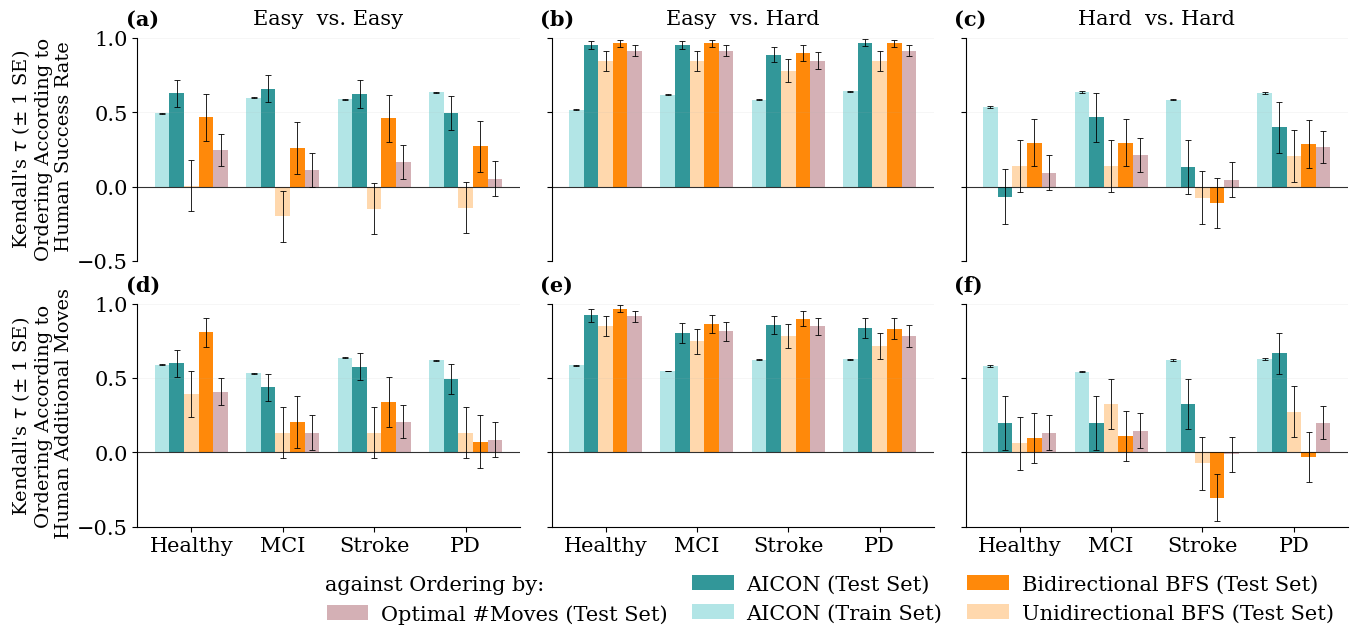

Saved plot to: c:\Users\Michael Migacev\Desktop\UNI\Wirklich_UNI\AICON\master-thesis-tol\master-thesis-tol\tower_of_london_plots\tables\boxed_remaining_2x3_5bars_super_despined.pdf


In [ ]:
def _configure_style() -> None:
    plt.rcParams.update({
        "font.family": "serif",
        "font.serif": ["Computer Modern Roman", "DejaVu Serif"],
        "axes.titlesize": 15,
        "axes.labelsize": 15,
        "font.size": 15,
        "xtick.labelsize": 15,
        "ytick.labelsize": 15,
        "figure.facecolor": "white",
        "axes.facecolor": "white",
    })

def _style_box_axes(ax: plt.Axes) -> None:
    for spine in ax.spines.values():
        spine.set_visible(False)
        spine.set_linewidth(0.8)
    ax.spines['left'].set_visible(True)
    ax.spines['bottom'].set_visible(True) 
    ax.grid(axis="y", alpha=0.15, linewidth=0.5); ax.axhline(0, color="black", linewidth=0.8, alpha=0.8)

def _style_box_axes_top(ax: plt.Axes) -> None:
    for spine in ax.spines.values():
        spine.set_visible(False)
        spine.set_linewidth(0.8)
    ax.spines['left'].set_visible(True)
    ax.spines['bottom'].set_visible(True) 
    ax.grid(axis="y", alpha=0.15, linewidth=0.5); ax.axhline(0, color="black", linewidth=0.8, alpha=0.8)

def _style_box_axes_bottom(ax: plt.Axes) -> None:
    for spine in ax.spines.values():
        spine.set_visible(False)
        spine.set_linewidth(0.8)
    ax.spines['left'].set_visible(True)
    ax.spines['bottom'].set_visible(True) 
    ax.grid(axis="y", alpha=0.15, linewidth=0.5); ax.axhline(0, color="black", linewidth=0.8, alpha=0.8)

def _draw_panel(
    ax: plt.Axes,
    df: pd.DataFrame,
    selection: str,
    metric: str,
    title: str,
    panel_letter: str | None = None,
    top_row: bool = False,
    y_limits: tuple[float, float] = (0.0, 1.0),
) -> None:
    x = np.arange(len(PATIENT_ORDER_LOCAL))
    n_series = len(SERIES_INFO_LOCAL)
    bar_width = (1.0 / n_series) * 0.8
    offsets = (np.arange(n_series) - (n_series - 1) / 2) * bar_width
    for offset, (mean_col, std_col, label, color) in zip(offsets, SERIES_INFO_LOCAL):
        means = []; errors = []
        for patient_group in PATIENT_ORDER_LOCAL:
            row = _get_row(df, selection, metric, patient_group)
            means.append(float(row[mean_col])); errors.append(_get_stderr(float(row[std_col]), selection))
        ax.bar(
            x + offset,
            means,
            width=bar_width,
            yerr=errors,
            capsize=2,
            color=color,
            edgecolor="none",
            linewidth=0,
            label=label,
            error_kw={"elinewidth": 0.6, "capthick": 0.6},
        )
    ax.set_title(title, loc="center", pad=10, fontfamily="serif")
    if panel_letter is not None:
        ax.text(
            -0.03,
            1.04,
            f"({panel_letter})",
            transform=ax.transAxes,
            ha="left",
            va="bottom",
            fontfamily="serif",
            fontweight="bold",
        )
    ax.set_xticks(x); ax.set_xticklabels(PATIENT_ORDER_LOCAL)
    ax.set_ylim(*y_limits); _style_box_axes(ax)
    if top_row:
        ax.tick_params(labelbottom=False, bottom=False)
        ax.spines['bottom'].set_visible(False)


_configure_style()
summary_frame_local = _load_all_tables(CSV_FOLDER_LOCAL, SELECTION_SUFFIXES_LOCAL)

fig_b, axes_b = plt.subplots(2, 3, figsize=(14, 6.5), sharex=True, sharey=True)
selections_by_col = ["easy_v_easy", "easy_v_hard", "hard_v_hard"]
col_titles = ["Easy  vs. Easy", "Easy  vs. Hard", "Hard  vs. Hard"]
for col_idx, (selection, col_title) in enumerate(zip(selections_by_col, col_titles)):
    _draw_panel(
        axes_b[0, col_idx],
        summary_frame_local,
        selection,
        "success_rate_rev",
        col_title,
        panel_letter=chr(97 + col_idx),
        top_row=True,
        y_limits=(-0.5, 1.0),
    )
    _draw_panel(
        axes_b[1, col_idx],
        summary_frame_local,
        selection,
        "mean_extra_moves_on_success",
        "",
        panel_letter=chr(100 + col_idx),
        top_row=False,
        y_limits=(-0.5, 1.0),
    )
from matplotlib.patches import Rectangle

handles_b, labels_b = axes_a[0].get_legend_handles_labels()
legend_order = [
    "Optimal #Moves (Test Set)",
    "AICON (Test Set)",
    "AICON (Train Set)",
    "Bidirectional BFS (Test Set)",
    "Unidirectional BFS (Test Set)",
]
ordered_handles = [handles_a[labels_a.index(label)] for label in legend_order]

dummy_handle = Rectangle(
    (0, 0), 0, 0, fill=False, linewidth=0, alpha=0, edgecolor="none"
)

# Prepend the dummy so the legend grid becomes 2 rows × 3 cols
all_handles = [dummy_handle] + ordered_handles
all_labels  = ["     "] + legend_order

ordered_handles = [handles_b[labels_b.index(label)] for label in legend_order]
fig_b.text(
    0.051,
    0.66,
    "Kendall's $\\tau$ ($\\pm$ 1 SE)\nOrdering According to\n Human Success Rate",
    rotation=90,
    ha="center",
    va="center",
    fontfamily="serif",
    fontsize=14,
)
fig_b.text(
    0.051,
    0.25,
    "Kendall's $\\tau$ ($\\pm$ 1 SE)\nOrdering According to\n Human Additional Moves",
    rotation=90,
    ha="center",
    va="center",
    fontfamily="serif",
    fontsize=14,
)

fig_b.text(0.253, 0.004, "against Ordering by:", ha="left", va="top", fontfamily="serif")
fig_b.legend(
    all_handles,
    all_labels,
    frameon=False,
    ncols=3,
    loc="upper left",
    bbox_to_anchor=(0.256, 0.002),
    columnspacing=1.2,
    handletextpad=0.6,
    borderaxespad=-0.5,
)
fig_b.tight_layout(rect=(0.06, 0, 1, 0.91), h_pad=0.10)
out_b = CSV_FOLDER_LOCAL / "boxed_remaining_2x3_5bars_super_despined.pdf"
fig_b.savefig(out_b, dpi=300, bbox_inches="tight")
plt.show(); plt.close(fig_b)

print(f"Saved plot to: {out_b}")